# Load and clean the Los Angeles crime data

This notebook combines and cleans two Los Angeles Police Department CSV files. It saves the result as `data/crime_clean.parquet` for the later notebooks. The project question is: **which reported crimes were recorded as an arrest?**

The data stop at **February 29, 2024** for this project. The source contains later dates, but the number of records changes sharply when the LAPD moved to the National Incident-Based Reporting System (NIBRS) in March 2024. The city data portal says these historical files were frozen after that change, so later rows are not treated as directly comparable.

The notebook shows how many rows remain after each cleaning step. It checks repeated rows before removing them. Records with invalid coordinates are kept, but their latitude and longitude are marked as missing.


## 1. Imports and source files

This notebook uses pandas, NumPy, and Matplotlib, which are used in the course. The project style guide also allows saving the cleaned data as a Parquet file.

In [1]:
# load the libraries used for cleaning and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# read both crime files and check their sizes
source_2010 = '../data/Crime_Data_from_2010_to_2019_20260726.csv'
source_2020 = '../data/Crime_Data_from_2020_to_2024_20260726.csv'

df_2010 = pd.read_csv(source_2010, low_memory=False)
df_2020 = pd.read_csv(source_2020, low_memory=False)
print(f'2010-2019 source shape: {df_2010.shape}')
print(f'2020-2024 source shape: {df_2020.shape}')

2010-2019 source shape: (2133137, 28)
2020-2024 source shape: (1004894, 28)


In [3]:
# remove spaces from column names and compare the two files
df_2010.columns = df_2010.columns.str.strip()
df_2020.columns = df_2020.columns.str.strip()

print(f'Columns match: {list(df_2010.columns) == list(df_2020.columns)}')
print(f'Data types match: {df_2010.dtypes.equals(df_2020.dtypes)}')
print(f'Raw columns: {len(df_2010.columns)}')

Columns match: True
Data types match: True
Raw columns: 28


## 2. Combine the files, convert dates, and check repeated rows

A row counts as a duplicate only when every original field matches another row. The check does not remove rows based only on `DR_NO`, the report number. This keeps different records that might share a report number while removing repeated copies of the same full record. The summary below shows that the repeated rows are from 2016.

In [4]:
# combine the files, read the dates and count repeated rows
df = pd.concat([df_2010, df_2020], ignore_index=True)
del df_2010, df_2020

date_format = '%Y %b %d %I:%M:%S %p'
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format=date_format,
                                errors='coerce')
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format=date_format,
                                 errors='coerce')

raw_duplicate_extra = int(df.duplicated().sum())
raw_duplicate_rows = df.loc[df.duplicated(keep=False)]
duplicate_years = raw_duplicate_rows['DATE OCC'].dt.year.value_counts().sort_index()

print(f'Raw rows: {len(df):,}')
print(f'Raw exact duplicate extras: {raw_duplicate_extra:,}')
print(f'Raw exact duplicate rows including first copies: {len(raw_duplicate_rows):,}')
print('Duplicate rows by occurrence year:')
print(duplicate_years)

Raw rows: 3,138,031
Raw exact duplicate extras: 57,809
Raw exact duplicate rows including first copies: 115,618
Duplicate rows by occurrence year:
DATE OCC
2016    115618
Name: count, dtype: int64


In [5]:
# start a table of cleaning counts and check for missing dates
ledger = pd.DataFrame([
    {'step': 'raw concatenation', 'rows_before': len(df),
     'rows_after': len(df), 'rows_removed': 0}
])

date_missing = int(df['DATE OCC'].isna().sum() + df['Date Rptd'].isna().sum())
print(f'Missing parsed date values across both date columns: {date_missing:,}')

Missing parsed date values across both date columns: 0


## 3. Keep dates through February 2024

February 29, 2024 is the last date used in this project. Records from March 2024 and later are left out because the historical reporting files were frozen after the LAPD changed reporting systems.

In [6]:
# keep records through february 2024 and record the row counts
rows_before = len(df)
df = df[df['DATE OCC'] < '2024-03-01'].copy()
ledger = pd.concat([ledger, pd.DataFrame([{
    'step': 'occurrence date before 2024-03-01',
    'rows_before': rows_before,
    'rows_after': len(df),
    'rows_removed': rows_before - len(df)
}])], ignore_index=True)
print(f'Rows after cutoff: {len(df):,}')
print(f'Rows removed by cutoff: {rows_before - len(df):,}')

Rows after cutoff: 3,046,784
Rows removed by cutoff: 91,247


## 4. Check unusual and missing values

Some age values, such as 0 or a negative number, are special codes for an unknown or invalid age rather than a real age. These values become missing. Times written in four-digit hour-and-minute form are kept when valid. A zero latitude or longitude is also treated as missing. No report date occurs before its crime date, so all reporting delays are kept. These field problems do not cause a whole record to be removed.

In [7]:
# check unusual ages, times, locations and missing values
time_occ = pd.to_numeric(df['TIME OCC'], errors='coerce')
age = pd.to_numeric(df['Vict Age'], errors='coerce')
zero_coordinate = (df['LAT'] == 0) | (df['LON'] == 0)
negative_delay = df['Date Rptd'] < df['DATE OCC']
invalid_hhmm = (time_occ % 100 >= 60) | (time_occ > 2359)

anomaly_counts = pd.DataFrame({
    'count': [int((age < 0).sum()), int((age == 0).sum()),
              int(invalid_hhmm.sum()), int(zero_coordinate.sum()),
              int(negative_delay.sum())]
}, index=['negative age sentinels', 'zero age values', 'invalid HHMM',
          'zero coordinate pairs', 'negative reporting delays'])
print(anomaly_counts)

missing_before = (df.isna().mean() * 100).round(1)
print('Highest missingness before field cleaning:')
print(missing_before[missing_before > 0].sort_values(ascending=False).head(12))

                            count
negative age sentinels        861
zero age values            602373
invalid HHMM                    0
zero coordinate pairs        3148
negative reporting delays       0
Highest missingness before field cleaning:
Crm Cd 4          100.0
Crm Cd 3           99.8
Crm Cd 2           93.2
Cross Street       83.6
Weapon Used Cd     66.1
Weapon Desc        66.1
Mocodes            11.7
Vict Sex           10.5
Vict Descent       10.5
dtype: float64


In [8]:
# mark multiple offenses, unknown ages and missing locations
df['Multiple Offenses'] = df['Crm Cd 2'].notna()
df['Age Known'] = df['Vict Age'].between(1, 98)
df['Vict Age'] = df['Vict Age'].where(df['Age Known'], np.nan)
# zero coordinates are not usable locations
df.loc[zero_coordinate, ['LAT', 'LON']] = np.nan
age_unknown_pct = (~df['Age Known']).mean() * 100
print(f'Age unknown after sentinel handling: {age_unknown_pct:.1f}%')
print(f'Coordinates retained as rows with missing coordinates: {int(zero_coordinate.sum()):,}')

Age unknown after sentinel handling: 19.8%
Coordinates retained as rows with missing coordinates: 3,148


## 5. Keep the planned columns and categories

The cleaned file keeps the same planned columns as the original notebook. The numeric area column is removed because the area name contains the same information. Extra crime-code columns are summarized by `Multiple Offenses`. Weapon and victim categories are made consistent.

Only five status codes are used. `AA` and `JA` mean an arrest was recorded and receive an `Arrested` value of 1. `IC`, `AO`, and `JO` mean no arrest was recorded and receive a value of 0. Other status values are removed instead of being counted as no arrest.

In [9]:
# clean up weapon labels and victim and premise categories
df['Weapon Used Cd'] = df['Weapon Used Cd'].fillna(0).astype('int64')
df['Weapon Desc'] = df['Weapon Desc'].fillna('NONE').astype(str).str.strip().str.upper()
df['Weapon Desc'] = df['Weapon Desc'].replace('', 'NONE')
weapon_desc_map = {
    'STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)': 'STRONG-ARM/BODILY FORCE',
    'UNKNOWN WEAPON/OTHER WEAPON': 'UNKNOWN/OTHER WEAPON',
    'SEMI-AUTOMATIC PISTOL': 'SEMI-AUTO PISTOL',
    'KNIFE WITH BLADE 6INCHES OR LESS': 'KNIFE <= 6 IN',
    'M1-1 SEMI-AUTOMATIC ASSAULT RIFLE': 'SEMI-AUTO ASSAULT RIFLE',
    'MAC-10 SEMIAUTOMATIC ASSAULT WEAPON': 'MAC-10 ASSAULT WEAPON',
    'HECKLER & KOCH 93 SEMIAUTOMATIC ASSAULT RIFLE': 'HK-93 ASSAULT RIFLE',
    'SIMULATED GUN': 'SIMULATED FIREARM'
}
df['Weapon Desc'] = df['Weapon Desc'].replace(weapon_desc_map)
df['Vict Sex'] = df['Vict Sex'].where(df['Vict Sex'].isin(['M', 'F']), 'X')

descent_map = {
    'H': 'Hispanic', 'W': 'White', 'B': 'Black',
    'O': 'Other', 'I': 'Am Indian/Alaskan',
    'A': 'Asian/PI', 'C': 'Asian/PI', 'D': 'Asian/PI',
    'F': 'Asian/PI', 'G': 'Asian/PI', 'J': 'Asian/PI',
    'K': 'Asian/PI', 'L': 'Asian/PI', 'P': 'Asian/PI',
    'S': 'Asian/PI', 'U': 'Asian/PI', 'V': 'Asian/PI',
    'Z': 'Asian/PI'
}
df['Vict Descent'] = df['Vict Descent'].map(descent_map).fillna('Unknown')
df['Premis Desc'] = df['Premis Desc'].replace(
    {'MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)': 'MULTI-UNIT DWELLING'}
)
print('Standardized weapon, sex, descent, and premise fields.')

Standardized weapon, sex, descent, and premise fields.


In [10]:
# keep the selected case statuses and create the arrest label
allowed_status = ['IC', 'AA', 'AO', 'JA', 'JO']
rows_before = len(df)
df = df[df['Status'].isin(allowed_status)].copy()
ledger = pd.concat([ledger, pd.DataFrame([{
    'step': 'usable status codes',
    'rows_before': rows_before,
    'rows_after': len(df),
    'rows_removed': rows_before - len(df)
}])], ignore_index=True)
df['Arrested'] = df['Status'].isin(['AA', 'JA']).astype(int)
print(f'Rows removed for unsupported status values: {rows_before - len(df):,}')
print(df['Arrested'].value_counts())
print(f'Pre-dedup arrest rate: {df["Arrested"].mean():.4f}')

Rows removed for unsupported status values: 42
Arrested
0    2722848
1     323894
Name: count, dtype: int64
Pre-dedup arrest rate: 0.1063


## 6. Remove confirmed exact duplicate rows only

After the status check, the data contain 57,808 extra copies of complete rows, all from 2016. One copy of each record is kept. Rows are not removed based only on `DR_NO` because a matching report number does not prove that every field is the same.

In [11]:
# remove exact copies of rows and record how many were removed
rows_before = len(df)
duplicate_extra = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
ledger = pd.concat([ledger, pd.DataFrame([{
    'step': 'remove exact duplicate rows',
    'rows_before': rows_before,
    'rows_after': len(df),
    'rows_removed': rows_before - len(df)
}])], ignore_index=True)
print(f'Exact duplicate extras removed: {duplicate_extra:,}')
print(f'Final rows before column selection: {len(df):,}')

Exact duplicate extras removed: 57,808
Final rows before column selection: 2,988,934


In [12]:
# drop unused columns and show the cleaning counts
df = df.drop(columns=['Cross Street', 'AREA', 'Crm Cd 1', 'Crm Cd 2',
                     'Crm Cd 3', 'Crm Cd 4'])
df = df.reset_index(drop=True)

ledger

,step,rows_before,rows_after,rows_removed
0,raw concatenation,3138031,3138031,0
1,occurrence date before 2024-03-01,3138031,3046784,91247
2,usable status codes,3046784,3046742,42
3,remove exact duplicate rows,3046742,2988934,57808


## 7. Check the final data and make summary plots

The final file has 2,988,934 rows and 25 columns. A missing value means that the source did not provide a usable value. The notebook does not invent replacements for unknown ages, locations, or other missing source information.

In [13]:
# check the cleaned data size, column types and missing values
missing_after = (df.isna().mean() * 100).round(1)
print(f'Final row count: {len(df):,}')
print(f'Final column count: {len(df.columns)}')
print(f'Final arrest rate: {df["Arrested"].mean():.4f}')
print('Final schema:')
print(df.dtypes)
print('Final missingness above zero:')
print(missing_after[missing_after > 0].sort_values(ascending=False).head(12))

Final row count: 2,988,934
Final column count: 25
Final arrest rate: 0.1061
Final schema:
DR_NO                         int64
Date Rptd            datetime64[us]
DATE OCC             datetime64[us]
TIME OCC                      int64
AREA NAME                       str
Rpt Dist No                   int64
Part 1-2                      int64
Crm Cd                        int64
Crm Cd Desc                     str
Mocodes                         str
Vict Age                    float64
Vict Sex                        str
Vict Descent                    str
Premis Cd                   float64
Premis Desc                     str
Weapon Used Cd                int64
Weapon Desc                     str
Status                          str
Status Desc                     str
LOCATION                        str
LAT                         float64
LON                         float64
Multiple Offenses              bool
Age Known                      bool
Arrested                      int64
dtype: obj

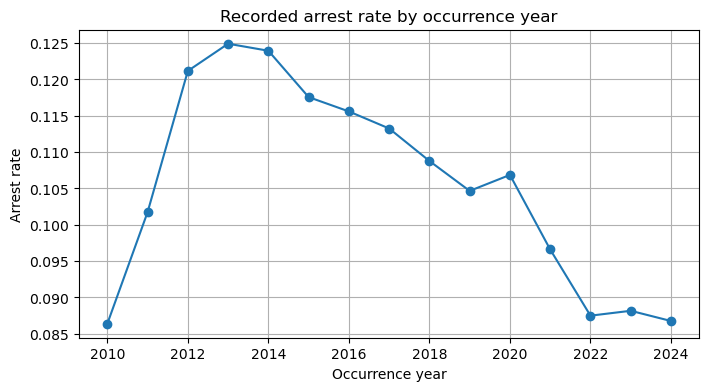

In [14]:
# plot the recorded arrest rate for each year
year_summary = df.assign(year=df['DATE OCC'].dt.year).groupby('year')['Arrested'].agg(
    ['count', 'mean']).reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(year_summary['year'], year_summary['mean'], marker='o')
ax.set_title('Recorded arrest rate by occurrence year')
ax.set_xlabel('Occurrence year')
ax.set_ylabel('Arrest rate')
ax.grid()
plt.show()

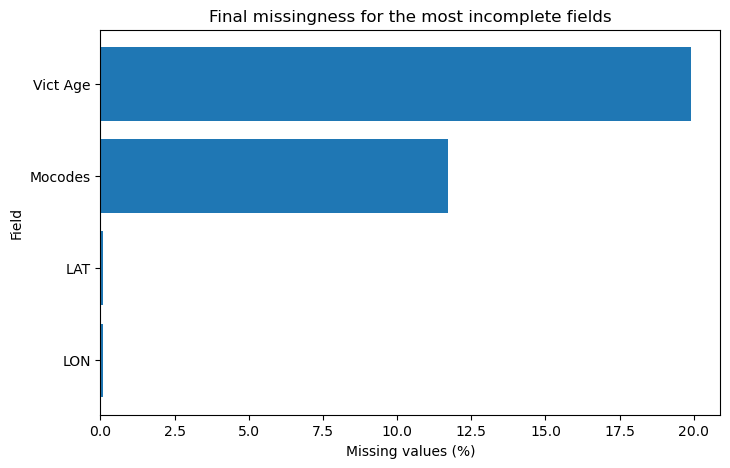

In [15]:
# plot the columns that still have missing values
missing_plot = missing_after[missing_after > 0].sort_values(ascending=True).tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(missing_plot.index, missing_plot.values)
ax.set_title('Final missingness for the most incomplete fields')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('Field')
plt.show()

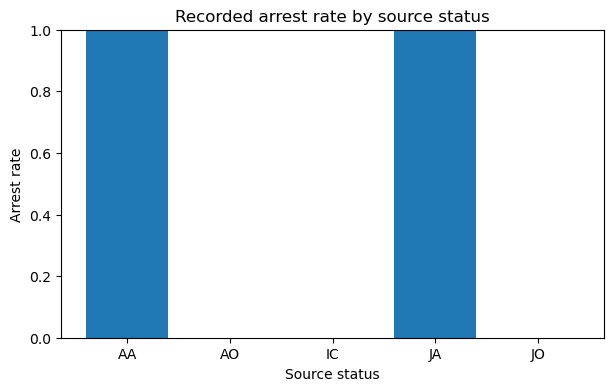

In [16]:
# plot the arrest rate for each case status
status_summary = df.groupby('Status')['Arrested'].agg(['count', 'mean']).reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(status_summary['Status'], status_summary['mean'])
ax.set_title('Recorded arrest rate by source status')
ax.set_xlabel('Source status')
ax.set_ylabel('Arrest rate')
ax.set_ylim(0, 1)
plt.show()

## 8. Save the cleaned data

The later notebooks can load the cleaned file with `pd.read_parquet('../data/crime_clean.parquet')`.

In [17]:
# save the cleaned data for the next notebooks
df.to_parquet('../data/crime_clean.parquet', index=False)
print('Wrote ../data/crime_clean.parquet')

Wrote ../data/crime_clean.parquet
